## Підготовка середовища та завантаження даних
Імпортуємо бібліотеки та завантажуємо датасет


In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

os.makedirs('figures', exist_ok=True)
os.makedirs('laba4/figures', exist_ok=True)

raw = load_wine()
X = pd.DataFrame(raw.data, columns=raw.feature_names)
y = raw.target
names = list(raw.target_names)

print("Розмірність вибірки:", X.shape)
print("Класи вин:", names)
X.head()


Розмірність вибірки: (178, 13)
Класи вин: ['class_0', 'class_1', 'class_2']


## Дослідницький аналіз даних
Перевіряємо пропуски та оцінюємо розкид значень ознак


Кількість пропусків: 0
                                mean     std     min     50%      max
alcohol                        13.00    0.81   11.03   13.05    14.83
malic_acid                      2.34    1.12    0.74    1.87     5.80
ash                             2.37    0.27    1.36    2.36     3.23
alcalinity_of_ash              19.49    3.34   10.60   19.50    30.00
magnesium                      99.74   14.28   70.00   98.00   162.00
total_phenols                   2.30    0.63    0.98    2.36     3.88
flavanoids                      2.03    1.00    0.34    2.13     5.08
nonflavanoid_phenols            0.36    0.12    0.13    0.34     0.66
proanthocyanins                 1.59    0.57    0.41    1.56     3.58
color_intensity                 5.06    2.32    1.28    4.69    13.00
hue                             0.96    0.23    0.48    0.96     1.71
od280/od315_of_diluted_wines    2.61    0.71    1.27    2.78     4.00
proline                       746.89  314.91  278.00  673.50  1680.

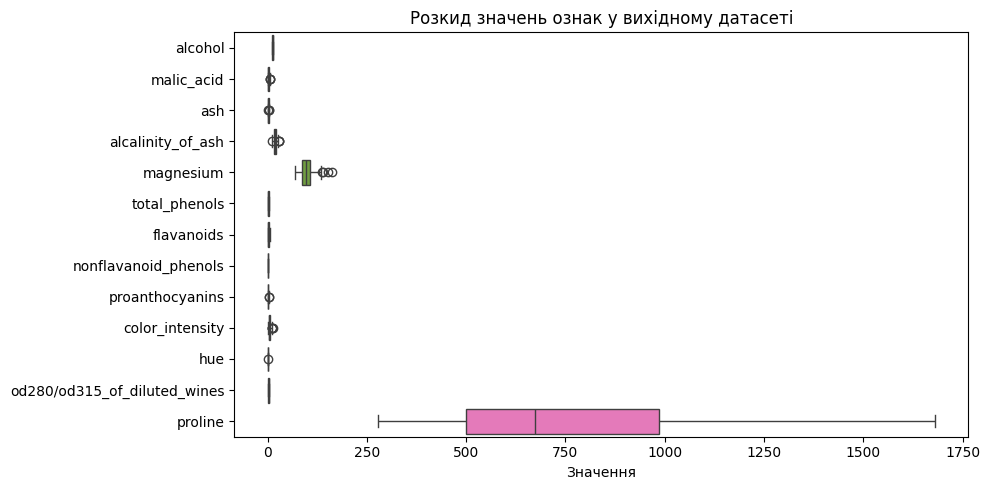

In [5]:
print("Кількість пропусків:", X.isna().sum().sum())
desc = X.describe().T[['mean', 'std', 'min', '50%', 'max']].round(2)
print(desc)

plt.figure(figsize=(10, 5))
sns.boxplot(data=X, orient='h')
plt.title("Розкид значень ознак у вихідному датасеті")
plt.xlabel("Значення")
plt.tight_layout()
plt.savefig('figures/eda_feature_boxplots.png')
plt.savefig('laba4/figures/eda_feature_boxplots.png')
plt.show()


## Масштабування ознак
Ознаки мають різний масштаб, тому застосовуємо StandardScaler


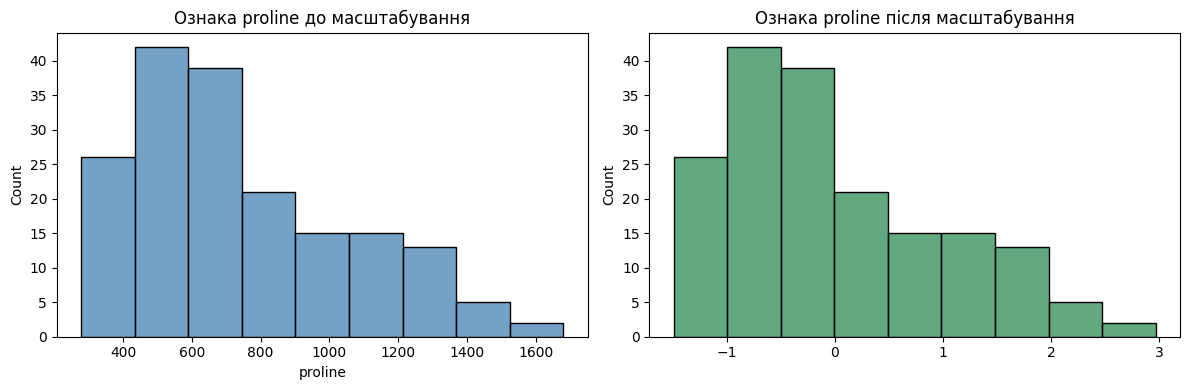

In [7]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(X['proline'], ax=axes[0], color='steelblue')
axes[0].set_title("Ознака proline до масштабування")

sns.histplot(X_scaled[:, 12], ax=axes[1], color='seagreen')
axes[1].set_title("Ознака proline після масштабування")
plt.tight_layout()
plt.savefig('figures/scaling_comparison.png')
plt.savefig('laba4/figures/scaling_comparison.png')
plt.show()


## Метод головних компонент



Кількість компонент для 90 відсотків дисперсії: 8


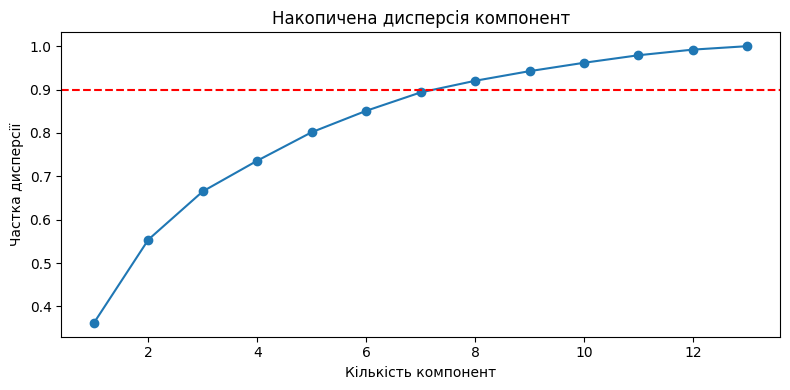

In [9]:
pca = PCA()
pca.fit(X_scaled)
cum = np.cumsum(pca.explained_variance_ratio_)

n90 = int(np.argmax(cum >= 0.90) + 1)
print("Кількість компонент для 90 відсотків дисперсії:", n90)

plt.figure(figsize=(8, 4))
plt.plot(range(1, 14), cum, marker='o')
plt.axhline(0.90, color='red', linestyle='--')
plt.title("Накопичена дисперсія компонент")
plt.xlabel("Кількість компонент")
plt.ylabel("Частка дисперсії")
plt.tight_layout()
plt.savefig('figures/pca_cumulative_variance.png')
plt.savefig('laba4/figures/pca_cumulative_variance.png')
plt.show()


## Проекція на дві головні компоненти
Будуємо графік перших двох компонент зі справжніми сортами вин


Дисперсія першої компоненти: 36.2
Дисперсія другої компоненти: 19.21


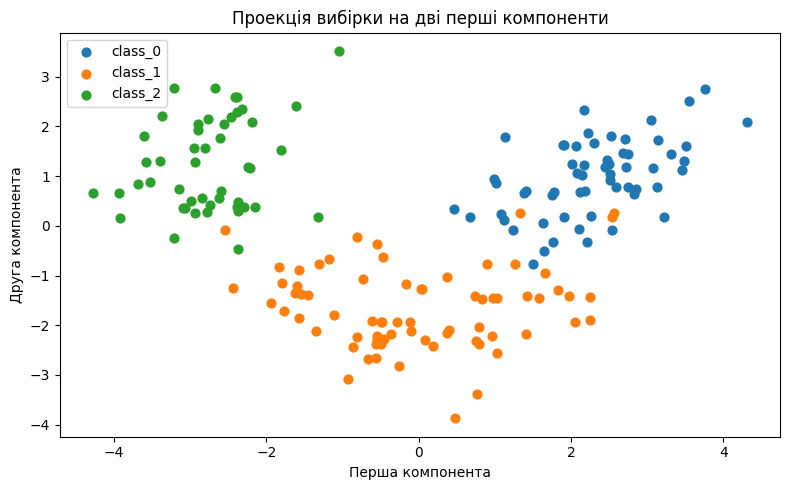

In [11]:
pca2 = PCA(n_components=2)
X_pca = pca2.fit_transform(X_scaled)

print("Дисперсія першої компоненти:", round(pca2.explained_variance_ratio_[0] * 100, 2))
print("Дисперсія другої компоненти:", round(pca2.explained_variance_ratio_[1] * 100, 2))

plt.figure(figsize=(8, 5))
for i in range(3):
    plt.scatter(X_pca[y == i, 0], X_pca[y == i, 1], label=names[i], s=40)
plt.title("Проекція вибірки на дві перші компоненти")
plt.xlabel("Перша компонента")
plt.ylabel("Друга компонента")
plt.legend()
plt.tight_layout()
plt.savefig('figures/pca_2d_true_cultivars.png')
plt.savefig('laba4/figures/pca_2d_true_cultivars.png')
plt.show()


## Кластеризація методом K-means
Шукаємо оптимальне значення k за допомогою інерції та силуету


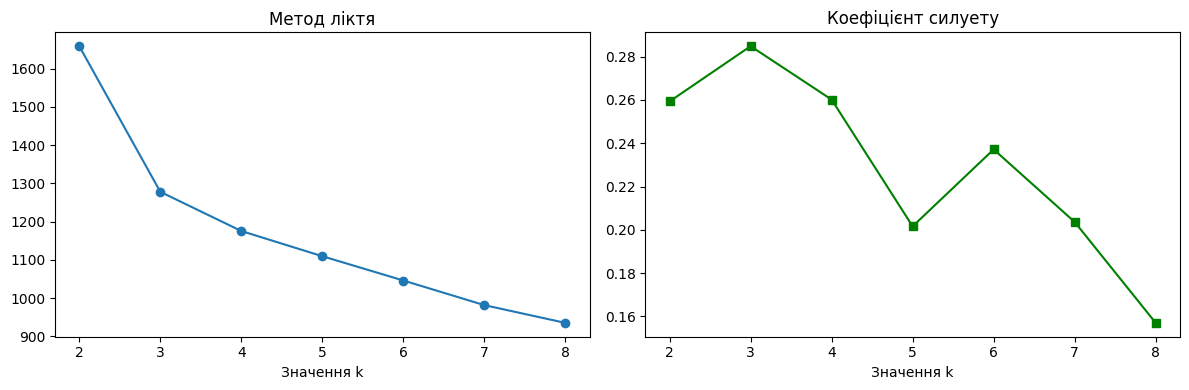

In [13]:
inertias = []
silhouettes = []
k_vals = list(range(2, 9))

for k in k_vals:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_vals, inertias, marker='o')
axes[0].set_title("Метод ліктя")
axes[0].set_xlabel("Значення k")

axes[1].plot(k_vals, silhouettes, marker='s', color='green')
axes[1].set_title("Коефіцієнт силуету")
axes[1].set_xlabel("Значення k")
plt.tight_layout()
plt.savefig('figures/kmeans_elbow_and_silhouette.png')
plt.savefig('laba4/figures/kmeans_elbow_and_silhouette.png')
plt.show()


## Навчання фінальної моделі та порівняння з реальними сортами
Фіксуємо k рівне трьом та зіставляємо знайдені кластери з мітками


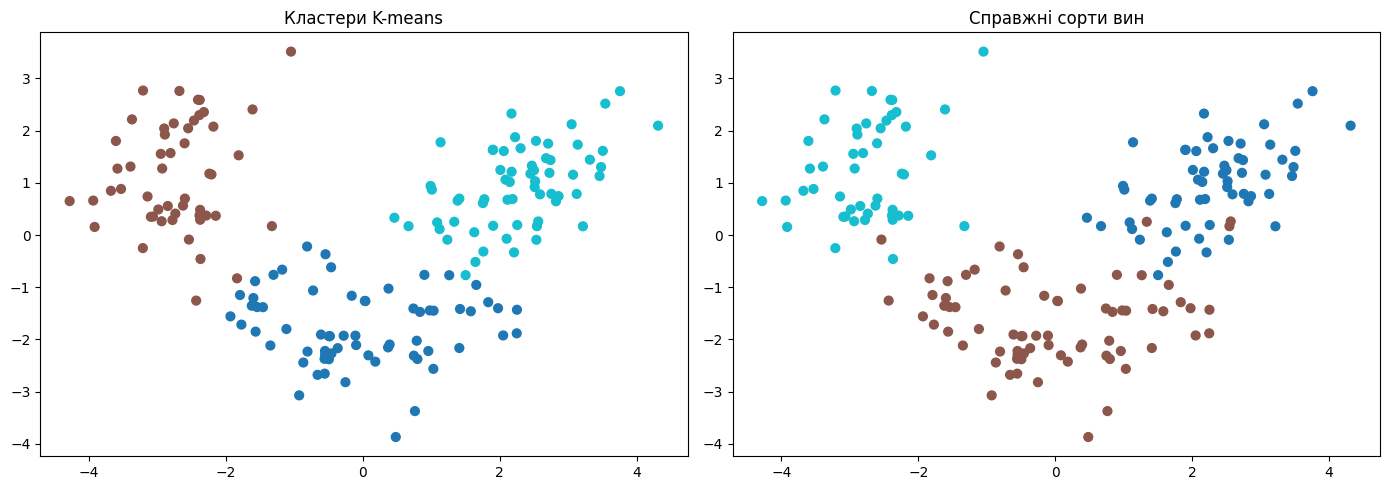

In [15]:
final_km = KMeans(n_clusters=3, n_init=10, random_state=42)
pred_labels = final_km.fit_predict(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=pred_labels, cmap='tab10', s=40)
axes[0].set_title("Кластери K-means")

axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='tab10', s=40)
axes[1].set_title("Справжні сорти вин")
plt.tight_layout()
plt.savefig('figures/kmeans_pca_comparison.png')
plt.savefig('laba4/figures/kmeans_pca_comparison.png')
plt.show()


## Оцінювання якості та перевірка стабільності
Розраховуємо силует та індекс ARI, а також перевіряємо стійкість моделі


In [17]:
sil = silhouette_score(X_scaled, pred_labels)
ari = adjusted_rand_score(y, pred_labels)

print("Силует на масштабованих даних:", round(sil, 4))
print("ARI на масштабованих даних:", round(ari, 4))
print("Розподіл за кластерами:", pd.Series(pred_labels).value_counts().to_dict())

seeds = [42, 7, 123, 777, 2024]
stab = []
for s in seeds:
    m = KMeans(n_clusters=3, n_init=10, random_state=s).fit(X_scaled)
    stab.append({
        'seed': s,
        'silhouette': round(silhouette_score(X_scaled, m.labels_), 4),
        'ari': round(adjusted_rand_score(y, m.labels_), 4)
    })
print(pd.DataFrame(stab))


Силует на масштабованих даних: 0.2849
ARI на масштабованих даних: 0.8975
Розподіл за кластерами: {0: 65, 2: 62, 1: 51}
   seed  silhouette     ari
0    42      0.2849  0.8975
1     7      0.2849  0.8975
2   123      0.2849  0.8975
3   777      0.2849  0.8975
4  2024      0.2849  0.8975


## Чутливість до масштабування ознак
Навчаємо K-means на сирих даних для порівняння якості


Силует без масштабування: 0.5711
ARI без масштабування: 0.3711


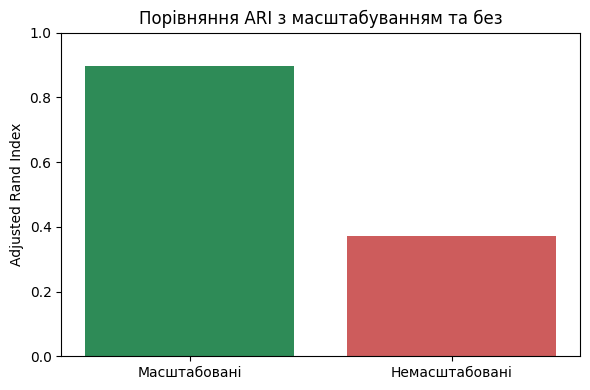

In [19]:
raw_km = KMeans(n_clusters=3, n_init=10, random_state=42)
raw_labels = raw_km.fit_predict(X)

raw_sil = silhouette_score(X, raw_labels)
raw_ari = adjusted_rand_score(y, raw_labels)

print("Силует без масштабування:", round(raw_sil, 4))
print("ARI без масштабування:", round(raw_ari, 4))

plt.figure(figsize=(6, 4))
plt.bar(["Масштабовані", "Немасштабовані"], [ari, raw_ari], color=['seagreen', 'indianred'])
plt.title("Порівняння ARI з масштабуванням та без")
plt.ylabel("Adjusted Rand Index")
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig('figures/scaled_vs_unscaled_comparison.png')
plt.savefig('laba4/figures/scaled_vs_unscaled_comparison.png')
plt.show()


## Зведена таблиця результатів
Зіставляємо підсумкові показники обох варіантів


In [21]:
summary = pd.DataFrame([
    {
        'Варіант': 'Масштабовані ознаки',
        'Silhouette': round(sil, 4),
        'ARI': round(ari, 4),
        'Розміри кластерів': str(pd.Series(pred_labels).value_counts().to_dict())
    },
    {
        'Варіант': 'Немасштабовані ознаки',
        'Silhouette': round(raw_sil, 4),
        'ARI': round(raw_ari, 4),
        'Розміри кластерів': str(pd.Series(raw_labels).value_counts().to_dict())
    }
])
print(summary.to_string(index=False))


              Варіант  Silhouette    ARI     Розміри кластерів
  Масштабовані ознаки      0.2849 0.8975 {0: 65, 2: 62, 1: 51}
Немасштабовані ознаки      0.5711 0.3711 {2: 69, 0: 62, 1: 47}
